In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd

matches = pd.read_csv("./datasets/matches.csv")

In [4]:
matches.isna().sum()

Unnamed: 0         0
date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
attendance       696
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [5]:
matches.shape

(1389, 28)

In [6]:
matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1389 entries, 0 to 1388
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1389 non-null   int64  
 1   date          1389 non-null   str    
 2   time          1389 non-null   str    
 3   comp          1389 non-null   str    
 4   round         1389 non-null   str    
 5   day           1389 non-null   str    
 6   venue         1389 non-null   str    
 7   result        1389 non-null   str    
 8   gf            1389 non-null   float64
 9   ga            1389 non-null   float64
 10  opponent      1389 non-null   str    
 11  xg            1389 non-null   float64
 12  xga           1389 non-null   float64
 13  poss          1389 non-null   float64
 14  attendance    693 non-null    float64
 15  captain       1389 non-null   str    
 16  formation     1389 non-null   str    
 17  referee       1389 non-null   str    
 18  match report  1389 non-null   str    
 

In [7]:
matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1389 entries, 0 to 1388
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1389 non-null   int64  
 1   date          1389 non-null   str    
 2   time          1389 non-null   str    
 3   comp          1389 non-null   str    
 4   round         1389 non-null   str    
 5   day           1389 non-null   str    
 6   venue         1389 non-null   str    
 7   result        1389 non-null   str    
 8   gf            1389 non-null   float64
 9   ga            1389 non-null   float64
 10  opponent      1389 non-null   str    
 11  xg            1389 non-null   float64
 12  xga           1389 non-null   float64
 13  poss          1389 non-null   float64
 14  attendance    693 non-null    float64
 15  captain       1389 non-null   str    
 16  formation     1389 non-null   str    
 17  referee       1389 non-null   str    
 18  match report  1389 non-null   str    
 

In [8]:
matches["date"] = pd.to_datetime(matches["date"])

In [9]:
# sort in chronological order
matches = matches.sort_values(by=["team", "date"], ignore_index=True)

In [10]:
matches.isna().sum()

Unnamed: 0         0
date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
attendance       696
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [11]:
matches = matches.drop(columns=["attendance", "Unnamed: 0"])

In [12]:
matches.isna().sum()

date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [13]:
matches = matches.drop(columns=["notes"])

In [14]:
matches.isna().sum()

date            0
time            0
comp            0
round           0
day             0
venue           0
result          0
gf              0
ga              0
opponent        0
xg              0
xga             0
poss            0
captain         0
formation       0
referee         0
match report    0
sh              0
sot             0
dist            1
fk              0
pk              0
pkatt           0
season          0
team            0
dtype: int64

In [93]:
matches["team"].value_counts()

team
Brighton and Hove Albion    72
Manchester United           72
Newcastle United            72
Southampton                 72
West Ham United             72
Arsenal                     71
Burnley                     71
Crystal Palace              71
Leeds United                71
Manchester City             71
Tottenham Hotspur           71
Wolverhampton Wanderers     71
Aston Villa                 70
Chelsea                     70
Everton                     70
Leicester City              70
Fulham                      38
Liverpool                   38
Sheffield United            38
West Bromwich Albion        38
Brentford                   34
Norwich City                33
Watford                     33
Name: count, dtype: int64

In [94]:
matches["opponent"].value_counts()

opponent
Liverpool          71
Southampton        71
Newcastle Utd      71
West Ham           70
Manchester Utd     70
Wolves             70
Tottenham          70
Brighton           70
Manchester City    69
Aston Villa        69
Leeds United       69
Burnley            69
Crystal Palace     69
Arsenal            69
Leicester City     68
Everton            68
Chelsea            68
Fulham             38
Sheffield Utd      38
West Brom          38
Brentford          32
Norwich City       31
Watford            31
Name: count, dtype: int64

In [95]:
# match up team and opponent names

# opponent : team
team_name_map = {
    "Liverpool": "Liverpool",
    "Southampton": "Southampton",
    "Newcastle Utd": "Newcastle United",
    "West Ham": "West Ham United",
    "Manchester Utd": "Manchester United",
    "Wolves": "Wolverhampton Wanderers",
    "Tottenham": "Tottenham Hotspur",
    "Brighton": "Brighton and Hove Albion",
    "Manchester City": "Manchester City",
    "Aston Villa": "Aston Villa",
    "Leeds United": "Leeds United",
    "Burnley": "Burnley",
    "Crystal Palace": "Crystal Palace",
    "Arsenal": "Arsenal",
    "Leicester City": "Leicester City",
    "Everton": "Everton",
    "Chelsea": "Chelsea",
    "Fulham": "Fulham",
    "Sheffield Utd": "Sheffield United",
    "West Brom": "West Bromwich Albion",
    "Brentford": "Brentford",
    "Norwich City": "Norwich City",
    "Watford": "Watford",
}

matches["opponent"] = matches["opponent"].replace(team_name_map)

In [97]:
matches["opponent"].value_counts()

opponent
Liverpool                   71
Southampton                 71
Newcastle United            71
West Ham United             70
Manchester United           70
Wolverhampton Wanderers     70
Tottenham Hotspur           70
Brighton and Hove Albion    70
Manchester City             69
Aston Villa                 69
Leeds United                69
Burnley                     69
Crystal Palace              69
Arsenal                     69
Leicester City              68
Everton                     68
Chelsea                     68
Fulham                      38
Sheffield United            38
West Bromwich Albion        38
Brentford                   32
Norwich City                31
Watford                     31
Name: count, dtype: int64

In [98]:
# split chronologically
from src import split as spl

train, valid, test = spl.split_data(matches)

In [99]:
test.tail()

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,dist,fk,pk,pkatt,season,team,rolling_gf,rolling_ga,rolling_xg,rolling_xga
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.2,0.76,1.98
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.2,1.0,0.80,1.76
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.2,0.76,1.66
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle United,...,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.8,1.2,0.84,1.66
1388,2022-04-24,14:00,Premier League,Matchweek 34,Sun,Away,L,0.0,1.0,Burnley,...,18.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.8,1.0,0.80,1.46


In [100]:
# features to use

features = ["team", "opponent", "venue"]

In [101]:
X_train, y_train = spl.split_label(train, features)
X_valid, y_valid = spl.split_label(valid, features)
X_test, y_test = spl.split_label(test, features)

In [102]:
results_label = {"W": 0, "L": 1, "D": 2}

y_train_encoded = y_train.map(results_label)
y_valid_encoded = y_valid.map(results_label)
y_test_encoded = y_test.map(results_label)

In [103]:
y_train_encoded

0       0
1       0
2       1
3       0
4       1
       ..
1362    0
1363    0
1364    2
1365    0
1366    1
Name: result, Length: 969, dtype: int64

In [104]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore").set_output(
    transform="pandas"
)

X_train_encoded = encoder.fit_transform(X_train)
X_valid_encoded = encoder.transform(X_valid)
X_test_encoded = encoder.transform(X_test)

In [105]:
X_train_encoded

,team_Arsenal,team_Aston Villa,team_Brentford,team_Brighton and Hove Albion,team_Burnley,team_Chelsea,team_Crystal Palace,team_Everton,team_Fulham,team_Leeds United,...,opponent_Norwich City,opponent_Sheffield United,opponent_Southampton,opponent_Tottenham Hotspur,opponent_Watford,opponent_West Bromwich Albion,opponent_West Ham United,opponent_Wolverhampton Wanderers,venue_Away,venue_Home
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1363,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1364,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Logistic Regression


In [106]:
# first training
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_encoded, y_train_encoded)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [107]:
predictions = log_reg.predict(X_valid_encoded)

In [108]:
from sklearn.metrics import accuracy_score

print(f"Accuracy: {accuracy_score(y_valid_encoded, predictions)}")

Accuracy: 0.5170731707317073


In [109]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_valid_encoded,
        predictions,
        labels=[0, 1, 2],
        target_names=["Win", "Loss", "Draw"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

         Win       0.51      0.68      0.58        71
        Loss       0.54      0.69      0.61        78
        Draw       0.36      0.07      0.12        56

    accuracy                           0.52       205
   macro avg       0.47      0.48      0.44       205
weighted avg       0.48      0.52      0.46       205



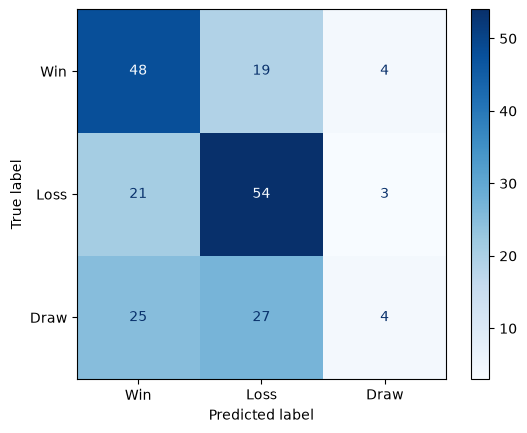

In [110]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_valid_encoded,
    predictions,
    labels=[0, 1, 2],
    display_labels=["Win", "Loss", "Draw"],
    cmap="Blues",
)

plt.show()

In [111]:
matches

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,dist,fk,pk,pkatt,season,team,rolling_gf,rolling_ga,rolling_xg,rolling_xga
0,2020-09-12,12:30,Premier League,Matchweek 1,Sat,Away,W,3.0,0.0,Fulham,...,13.6,2.0,0.0,0.0,2021,Arsenal,NaN,NaN,NaN,NaN
1,2020-09-19,20:00,Premier League,Matchweek 2,Sat,Home,W,2.0,1.0,West Ham United,...,15.3,0.0,0.0,0.0,2021,Arsenal,3.0,0.000000,1.800000,0.200000
2,2020-09-28,20:00,Premier League,Matchweek 3,Mon,Away,L,1.0,3.0,Liverpool,...,15.3,0.0,0.0,0.0,2021,Arsenal,2.5,0.500000,1.600000,1.050000
3,2020-10-04,14:00,Premier League,Matchweek 4,Sun,Home,W,2.0,1.0,Sheffield United,...,16.7,0.0,0.0,0.0,2021,Arsenal,2.0,1.333333,1.466667,1.766667
4,2020-10-17,17:30,Premier League,Matchweek 5,Sat,Away,L,0.0,1.0,Manchester City,...,18.2,2.0,0.0,0.0,2021,Arsenal,2.0,1.250000,1.200000,1.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.980000
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.2,1.000000,0.800000,1.760000
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.660000
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle United,...,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.8,1.200000,0.840000,1.660000


In [112]:
# add gf ga xg xga as features
# for each team - add a rolling average column 
# for each feature considering past 5 matches

from src import stats

matches = stats.compute_rolling(matches)

In [113]:
matches

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,dist,fk,pk,pkatt,season,team,rolling_gf,rolling_ga,rolling_xg,rolling_xga
0,2020-09-12,12:30,Premier League,Matchweek 1,Sat,Away,W,3.0,0.0,Fulham,...,13.6,2.0,0.0,0.0,2021,Arsenal,NaN,NaN,NaN,NaN
1,2020-09-19,20:00,Premier League,Matchweek 2,Sat,Home,W,2.0,1.0,West Ham United,...,15.3,0.0,0.0,0.0,2021,Arsenal,3.0,0.000000,1.800000,0.200000
2,2020-09-28,20:00,Premier League,Matchweek 3,Mon,Away,L,1.0,3.0,Liverpool,...,15.3,0.0,0.0,0.0,2021,Arsenal,2.5,0.500000,1.600000,1.050000
3,2020-10-04,14:00,Premier League,Matchweek 4,Sun,Home,W,2.0,1.0,Sheffield United,...,16.7,0.0,0.0,0.0,2021,Arsenal,2.0,1.333333,1.466667,1.766667
4,2020-10-17,17:30,Premier League,Matchweek 5,Sat,Away,L,0.0,1.0,Manchester City,...,18.2,2.0,0.0,0.0,2021,Arsenal,2.0,1.250000,1.200000,1.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.980000
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.2,1.000000,0.800000,1.760000
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.660000
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle United,...,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.8,1.200000,0.840000,1.660000


In [114]:
rolling_cols = [
    "rolling_gf",
    "rolling_ga",
    "rolling_xg",
    "rolling_xga",
]

In [115]:
features = ["team", "opponent", "venue", *rolling_cols]

(
    X_train_encoded,
    X_valid_encoded,
    X_test_encoded,
    y_train_encoded,
    y_valid_encoded,
    y_test_encoded,
) = spl.final_split(matches, features, encoder)

In [116]:
X_train_encoded.head()

,team_Arsenal,team_Aston Villa,team_Brentford,team_Brighton and Hove Albion,team_Burnley,team_Chelsea,team_Crystal Palace,team_Everton,team_Fulham,team_Leeds United,...,opponent_Watford,opponent_West Bromwich Albion,opponent_West Ham United,opponent_Wolverhampton Wanderers,venue_Away,venue_Home,rolling_gf,rolling_ga,rolling_xg,rolling_xga
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,NaN
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,3.0,0.000000,1.800000,0.200000
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2.5,0.500000,1.600000,1.050000
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2.0,1.333333,1.466667,1.766667
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.250000,1.200000,1.375000


In [117]:
# dealing with null values
from sklearn.impute import SimpleImputer


imputer = SimpleImputer(strategy="median")

X_train_encoded[rolling_cols] = imputer.fit_transform(X_train_encoded[rolling_cols])
X_valid_encoded[rolling_cols] = imputer.transform(X_valid_encoded[rolling_cols])
X_test_encoded[rolling_cols] = imputer.transform(X_test_encoded[rolling_cols])

In [118]:
X_train_encoded.isna().sum()

team_Arsenal                         0
team_Aston Villa                     0
team_Brentford                       0
team_Brighton and Hove Albion        0
team_Burnley                         0
team_Chelsea                         0
team_Crystal Palace                  0
team_Everton                         0
team_Fulham                          0
team_Leeds United                    0
team_Leicester City                  0
team_Liverpool                       0
team_Manchester City                 0
team_Manchester United               0
team_Newcastle United                0
team_Norwich City                    0
team_Sheffield United                0
team_Southampton                     0
team_Tottenham Hotspur               0
team_Watford                         0
team_West Bromwich Albion            0
team_West Ham United                 0
team_Wolverhampton Wanderers         0
opponent_Arsenal                     0
opponent_Aston Villa                 0
opponent_Brentford       

In [119]:
log_reg.fit(X_train_encoded, y_train_encoded)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Accuracy: 0.50732
              precision    recall  f1-score   support

         Win       0.50      0.65      0.56        71
        Loss       0.51      0.68      0.59        78
        Draw       0.50      0.09      0.15        56

    accuracy                           0.51       205
   macro avg       0.50      0.47      0.43       205
weighted avg       0.51      0.51      0.46       205



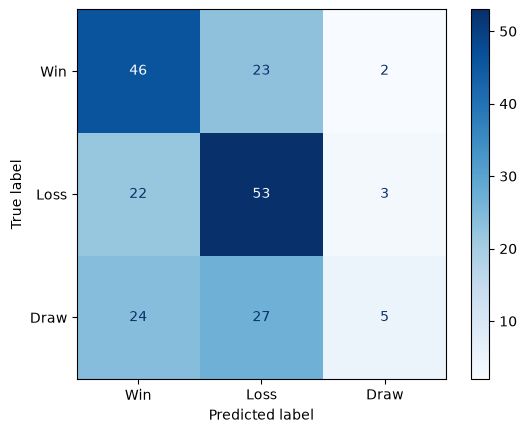

In [ ]:
from src import evaluation as eval
eval.evaluate(log_reg, X_valid_encoded, y_valid_encoded, predictions)

### Random Forest Classifier

In [121]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

forest.fit(X_train_encoded, y_train_encoded)

predictions = forest.predict(X_valid_encoded)

Accuracy: 0.48293
              precision    recall  f1-score   support

         Win       0.47      0.54      0.50        71
        Loss       0.49      0.78      0.60        78
        Draw       0.00      0.00      0.00        56

    accuracy                           0.48       205
   macro avg       0.32      0.44      0.37       205
weighted avg       0.35      0.48      0.40       205



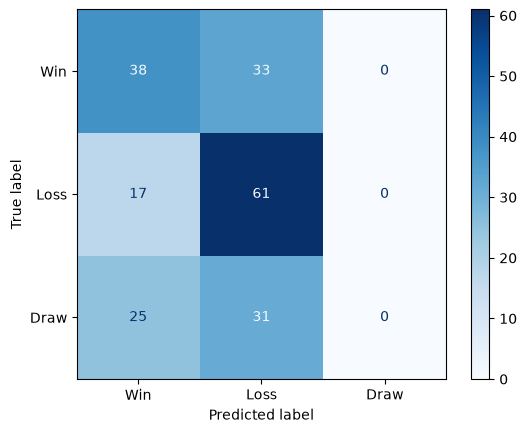

In [122]:
eval.evaluate(forest, X_valid_encoded, y_valid_encoded, predictions)

In [123]:
log_reg.score(X_valid_encoded, y_valid_encoded)

0.5073170731707317

In [124]:
forest.score(X_valid_encoded, y_valid_encoded)

0.48292682926829267

### Create raw data for pipeline

In [136]:
from src import split as spl
from src import pipeline as pipe

train, valid, test = spl.split_data(matches)

features = pipe.categorical_cols + pipe.numeric_cols
label_map = {"W": 0, "L": 1, "D": 2}

X_train_raw = train[features]
X_valid_raw = valid[features]

y_train_encoded = train["result"].map(label_map)
y_valid_encoded = valid["result"].map(label_map)

In [137]:
pipe.forest_pipeline.fit(X_train_raw, y_train_encoded)

predictions = pipe.forest_pipeline.predict(X_valid_raw)

print("Validation accuracy:", pipe.forest_pipeline.score(X_valid_raw, y_valid_encoded))

Validation accuracy: 0.45365853658536587


### GridSearchCV on Forest

In [151]:
from src import grid_search as gs

forest_gs = gs.run_gs(pipe.forest_pipeline, matches, X_train_raw)

In [152]:
forest_gs.fit(X_train_raw, y_train_encoded)

best_forest = forest_gs.best_estimator_

# print("Best parameters:", forest_gs.best_params_)
print("Best CV macro F1:", forest_gs.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV macro F1: 0.4007297188967042


In [153]:
from sklearn.metrics import classification_report

predictions = best_forest.predict(X_valid_raw)

print(
    classification_report(
        y_valid_encoded,
        predictions,
        labels=[0, 1, 2],
        target_names=["Win", "Loss", "Draw"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

         Win       0.45      0.56      0.50        71
        Loss       0.47      0.59      0.53        78
        Draw       0.37      0.12      0.19        56

    accuracy                           0.45       205
   macro avg       0.43      0.43      0.40       205
weighted avg       0.44      0.45      0.42       205



### XGBoost

In [154]:
pipe.xgb_pipeline.fit(X_train_raw, y_train_encoded)
xgb_predictions = pipe.xgb_pipeline.predict(X_valid_raw)

print(
    classification_report(
        y_valid_encoded,
        xgb_predictions,
        labels=[0, 1, 2],
        target_names=["Win", "Loss", "Draw"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

         Win       0.47      0.59      0.53        71
        Loss       0.49      0.64      0.55        78
        Draw       0.54      0.12      0.20        56

    accuracy                           0.48       205
   macro avg       0.50      0.45      0.43       205
weighted avg       0.50      0.48      0.45       205



### GridSearchCV on XGBoost

In [155]:
xgb_gs = gs.run_gs(pipe.xgb_pipeline, matches, X_train_raw)

In [ ]:
xgb_gs.fit(X_train_raw, y_train_encoded)

best_xgb = xgb_gs.best_estimator_

# print("Best parameters:", xgb_gs.best_params_)
print(f"Best CV macro F1: {xgb_gs.best_score_}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV macro F1: 0.40091833530091653


### GridSearchCV on Logistic Regression

In [165]:
lr_gs = gs.run_gs(pipe.logreg_pipeline ,matches, X_train_raw)

In [167]:
lr_gs.fit(X_train_raw, y_train_encoded)

best_lr = lr_gs.best_estimator_

print(f"Best macro F1: {lr_gs.best_score_}")

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best macro F1: 0.41908092565231597


In [168]:
# summary (scoring based on macro F1)
from sklearn.metrics import f1_score

# logistic regression
lr_pred = log_reg.predict(X_valid_encoded)
print(f"Macro F1 score for LR: {f1_score(
    y_valid_encoded,
    lr_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
):.3f}")

# random forest
rf_pred = best_forest.predict(X_valid_raw)
print(f"Macro F1 score for Random Forest: {f1_score(
    y_valid_encoded,
    rf_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
):.3f}")

# xgboost
xgb_pred = best_xgb.predict(X_valid_raw)
print(f"Macro F1 score for XGBoost: {f1_score(
    y_valid_encoded,
    xgb_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
):.3f}")

Macro F1 score for LR: 0.434
Macro F1 score for Random Forest: 0.404
Macro F1 score for XGBoost: 0.405


In [164]:
matches.columns

Index(['date', 'time', 'comp', 'round', 'day', 'venue', 'result', 'gf', 'ga',
       'opponent', 'xg', 'xga', 'poss', 'captain', 'formation', 'referee',
       'match report', 'sh', 'sot', 'dist', 'fk', 'pk', 'pkatt', 'season',
       'team', 'rolling_gf', 'rolling_ga', 'rolling_xg', 'rolling_xga'],
      dtype='str')